#### AutoMPG
- 398 개의 instance
- 7 개의 feature
    - 연비를 target으로 설정
    - 입력 feature는 weight만 사용하여 선형회귀 모델 생성

In [14]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import torch
from torch import nn, optim
from torch.utils.data import TensorDataset, DataLoader

from sklearn.model_selection import train_test_split
from sklearn.metrics import *
from sklearn.preprocessing import MinMaxScaler

In [ ]:
device = 'cuda' if torch.cuda.is_available() else 'cpu'

'cpu'

#### Define make_DataSet, train, evaluate, learning_curve

In [19]:
def make_DataSet(x_train, x_val, y_train, y_val, batch_size= 32):
    x_train_tensor = torch.tensor(x_train, dtype= torch.float32)
    y_train_tensor = torch.tensor(y_train, dtype= torch.float32).view(-1,1)
    x_val_tensor = torch.tensor(x_val, dtype= torch.float32)
    y_val_tensor = torch.tensor(y_val, dtype= torch.float32).view(-1,1)

    train_dataset = TensorDataset(x_train_tensor, y_train_tensor)
    test_dataset = TensorDataset(x_val_tensor, y_val_tensor)

    train_loader = DataLoader(train_dataset, batch_size= batch_size, shuffle=True)
    test_loader = DataLoader(test_dataset, batch_size= batch_size, shuffle=False)

    return train_loader, test_loader

In [10]:
def train(dataloader, model, loss_fn, optimizer, device):
    size = len(dataloader.dataset)
    num_batches = len(dataloader)
    tr_loss = 0
    
    model.train()
    for x, y in dataloader:
        x, y = x.to(device), y.to(device)
        pred = model(x)
        loss = loss_fn(pred, y)
        tr_loss += loss
        loss.backward()
        optimizer.step()
        optimizer.zero_grad()
    tr_loss /= num_batches

    return tr_loss.item()

In [11]:
def evalutate(dataloader, model, loss_fn, optimizer, device):
    model.eval()
    with torch.no_grad():
        x, y = x.to(device), y.to(device)
        pred = model(x)
        val_loss = loss_fn(pred, y).item()

    return val_loss, pred

In [12]:
def learning_curve(tr_loss_list, val_loss_list):
    epochs = list(range(1, len(tr_loss_list)+1))
    plt.plot(epochs, tr_loss_list, label= 'train error', marker= '.')
    plt.plot(epochs, val_loss_list, label= 'val error', marker= '.')
    plt.xlabel('Epochs')
    plt.ylabel('Loss')
    plt.legend()
    plt.grid()
    plt.show()

#### Input Dataset

In [ ]:
data = sns.load_dataset('mpg')

print(data.head())
print(data.shape)
print(data.isnull().sum())  # 무게에는 결측치 존재하지 않음

    mpg  cylinders  displacement  horsepower  weight  acceleration  \
0  18.0          8         307.0       130.0    3504          12.0   
1  15.0          8         350.0       165.0    3693          11.5   
2  18.0          8         318.0       150.0    3436          11.0   
3  16.0          8         304.0       150.0    3433          12.0   
4  17.0          8         302.0       140.0    3449          10.5   

   model_year origin                       name  
0          70    usa  chevrolet chevelle malibu  
1          70    usa          buick skylark 320  
2          70    usa         plymouth satellite  
3          70    usa              amc rebel sst  
4          70    usa                ford torino  
(398, 9)
mpg             0
cylinders       0
displacement    0
horsepower      6
weight          0
acceleration    0
model_year      0
origin          0
name            0
dtype: int64


In [32]:
# 자동차 무게와 연비만 선택
target = 'mpg'
feature = 'weight'
x = data.loc[:, [feature]]
# 단일변수회귀모델의 단순 x 데이터는 series로 출력 되기 때문에 
# 대괄호를 하나 더 붙인 [:, [feature]]으로 데이터프레임으로 변환
y = data.loc[:, target]

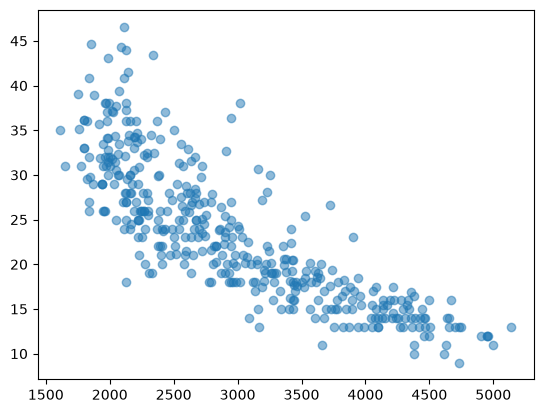

In [33]:
# 그래프 보기
plt.scatter(x, y, alpha=0.5)

In [34]:
x_train, x_val, y_train, y_val = train_test_split(x, y, test_size= .2, random_state= 42)

scaler = MinMaxScaler()

x_train = scaler.fit_transform(x_train)  
x_val = scaler.transform(x_val)

y_train = y_train.values
y_val = y_val.values

train_loader, test_loader = make_DataSet(x_train, x_val, y_train, y_val, batch_size= 32)

In [ ]:
# 모델 선언
# LR, EPOCH 등의 하이퍼파라미터 변경 시, model 선언 cell만 초기화할 수 있도록 같은 cell에 배치
LR = 1e-2
EPOCH = 100

n_feature = x.shape[1]
model = nn.Sequential(nn.Linear(n_feature, 16),
    nn.ReLU(),
    nn.Linear(16, 1)
    ).to(device)
loss_fn = nn.MSELoss()
optimizer = optim.Adam(model.parameters(), lr= LR)

In [ ]:
# 학습

tr_loss_list, val_loss_list = [], []

for ep in range